# Implementing Binary Dasymetric Interpolation
## Following an NHGIS-like Methodology 

In [1]:
import os

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tobler.area_weighted import area_interpolate
from tobler.dasymetric import extract_raster_features
from tobler.util import h3fy

%load_ext watermark
%watermark -a 'eli knaap' -v -d -u -p tobler,geopandas,rasterio

Author: eli knaap

Last updated: 2026-10-31

Python implementation: CPython
Python version       : 3.14.10
IPython version      : 9.18.0

tobler   : 0.14.1.dev83+gfb0403854.d20261031
geopandas: 1.2.0
rasterio : 1.5.2



**Note**: This notebook relies on functionality from the [`contextily`](https://contextily.readthedocs.io/en/latest/) package that provides convenient basemaps for geospatial plots, the [`osmnx`](https://osmnx.readthedocs.io/en/stable/) package that provide an access to OpenStreetMap data, and the [`cenpy`](https://cenpy-devs.github.io/cenpy/) package that provide a convenient interface to the U.S. Census API. These can be installed with  
  
`pip install contextily osmnx cenpy`     
or    
`conda install contextily osmnx cenpy -c conda-forge`

In [2]:
import osmnx as ox

ox.settings.use_cache = True
ox.settings.cache_folder = "./user-guide_osmnx_cache"

[NHGIS uses](https://www.nhgis.org/documentation/time-series/2000-blocks-to-2010-geog#advanced-model) a two step process, in which they first apply a binary dasymetric filter, then apply target density weighting. Here we will follow a similar strategy, relplicating their BD filtering (albeit with slightly different open data and replicable, open source tooling) before carrying out a simpler areal interpolation.

>In NHGIS's BD model for 2000 block data, the inhabited zone consists of all areas that are at least 5% developed impervious surface (within each 30-meter square cell of NLCD 2001 data) and lie within 300 feet of a residential road center line2 but not in a water body, using road definitions and water polygons from the 2010 TIGER/Line Shapefiles.

so we'll start by grabbing residential streets from OSM, buffering them out 300 feet, then using that geometry to select the impervious surfaces within

In [3]:
rside_streets = ox.features_from_place(
    "Riverside County, California", tags={"highway": "residential"}
)
rside_streets = rside_streets.to_crs(2230)
rside_streets = rside_streets.set_geometry(rside_streets.buffer(300))

In [4]:
rside_streets.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 56113 entries, ('way', np.int64(5942156)) to ('way', np.int64(1573783929))
Columns: 211 entries, geometry to cycleway:right:segregated
dtypes: geometry(1), str(210)
memory usage: 95.5 MB


Now we use the street buffers to extract any cells between 5 and 100% impervious surface

First, download [NLCD](https://www.mrlc.gov/data) data from here: https://s3-us-west-2.amazonaws.com/mrlc/NLCD_2016_Impervious_L48_20190405.zip, then unzip the archive and pass the path to the `img` file to tobler's `extract_raster_features` function

In [5]:
nlcd_path = "s3://spatial-ucr/nlcd/impervious/nlcd_impervious_2016.tif"

In [6]:
import rasterio

with rasterio.Env(AWS_NO_SIGN_REQUEST="YES"):
    urban_rside = extract_raster_features(
        rside_streets, nlcd_path, pixel_values=list(range(5, 101)), collapse_values=True
    )

In [7]:
urban_rside.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 23592 entries, 0 to 23591
Data columns (total 1 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   geometry  23592 non-null  geometry
dtypes: geometry(1)
memory usage: 184.4 KB


In [8]:
urban_rside = urban_rside.to_crs(2230)

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

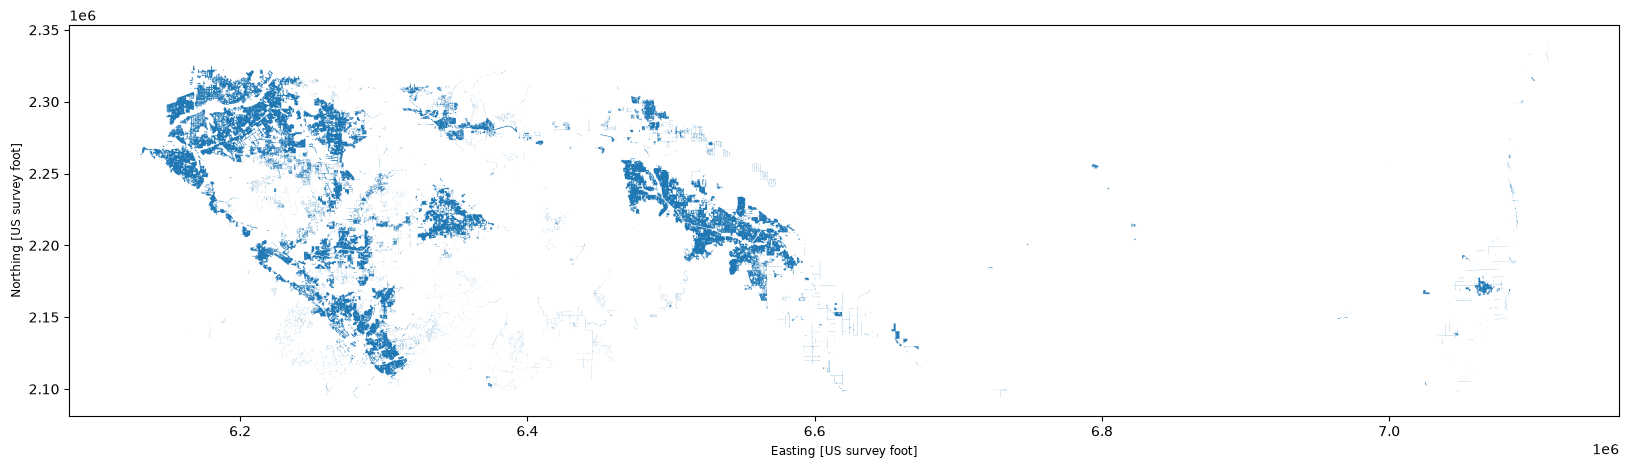

In [9]:
fig, ax = plt.subplots(figsize=(20, 14))
urban_rside.plot(ax=ax)

This geodataframe represents the areas that meet both criteria NHGIS suggests

Now we need some census data to transfer geometries. Lets grab tract-level population counts using cenpy

In [10]:
from cenpy import products, set_sitekey

set_sitekey(os.environ["CENSUS_API_KEY"])  # you need to provide your own API key

acs = products.ACS(2017)
rside_census = acs.from_county("Riverside County", variables=["B25077_001E"])
rside_census = rside_census.to_crs(2230)

rside_census.plot()

TypeError: sjoin() got an unexpected keyword argument 'op'

And lets generate some synthetic zones to transfer this population data into using h3 hexagons

In [ ]:
rside_hex = h3fy(rside_census, resolution=8)
rside_hex.plot()

Ok, now all that's left is to clip our input census data, "restricting" it to the locations NLCD defines as 5-100% impervious. To do so, we just need to clip the census data using our extracted urban features as a mask

The commented cell below takes hours and hours because geopandas current clip function is very inefficient for these data--**dont uncomment it!**

In [ ]:
# rside_dasy = gpd.clip(rside_census, urban_rside)

Instead, lets define a more efficient clip operation using the spatial index

In [ ]:
def iterclip(source, mask):
    tree = mask.sindex
    features = []
    for i, row in source.iterrows():
        query = tree.query(source.geometry.iloc[i], predicate="intersects").tolist()
        submask = mask[mask.index.isin(query)]
        single = gpd.GeoDataFrame(row.to_frame().T, crs=source.crs)
        features.append(gpd.clip(single, submask))
    frame = gpd.GeoDataFrame(pd.concat(features), crs=source.crs)
    return frame

In [ ]:
dasy = iterclip(rside_census, urban_rside)

Clipping census geometries by the urban features leaves the census attributes intact but reshapes them. If a census tract had 2000 people in it and covered 1 sqmi, but only a quarter mile of the tract was urbanized, the new geodataframe effectively shows these 2000 people occupying the quarter mile. By passing these new data to the `areal_interpolate` function, we're still assuming that population density is constant across our new geometries (a condition that may not be true in reality) but that assumption is much more plausible than when using original census geometries. 

In [ ]:
dasy.plot()

In [ ]:
dasy.B25077_001E = dasy.B25077_001E.fillna(0).astype(int)

In [ ]:
dasy.B25077_001E

In [ ]:
interp = area_interpolate(dasy, rside_hex, extensive_variables=["B25077_001E"])

In [ ]:
interp["plot"] = interp.B25077_001E.apply(np.log1p)

In [ ]:
fig, ax = plt.subplots(figsize=(20, 20))
interp.to_crs(3857).plot("plot", ax=ax, alpha=0.4, tiles=True)
ax.axis("off")

And there we have it. Riverside's 2017 population estimated at a regular hexgrid